# Thermodynamic Uncertainty Relations (TUR)

In this notebook, we will explore system, which in the overdamped limit coincides with the model discussed in [1], which violates the TUR. We will try to find a regime, in which the underdamped system obeys TUR due to the added inertia.

## The system

Suppose we have a system with two degrees of freedom $x,y$. There is a harmonic potential energy 
$$U(x,y) = \frac{1}{2} k(y)x^2,$$
with $k(y)$ being periodic:
$$k'(y) = \begin{cases}-\text{const.}, & \text{phase 1},\\ 0, & \text{phase 2}, \\ +\text{const.}, & \text{phase 3},\\ 0, & \text{phase 4}.\end{cases}$$
Also suppose that each of the two degrees of freedom is at different temperature, the $y$ degree at $T_c$, while the $x$ degree at $T(y)$, which is again periodic. We would like to preserve reversibility of the system (i.e. from the point of the system the $k(y)$ and $T(y)$ seem same in both directions of $y$), therefore we would like to have $T(y)$ with opposing phase (maximum of $T(y)$ lies exactly where is the minimum of $k(y)$). Lastly, we suppose that the inertia of the system in the $x$-direction is neglectible, i.e. the system is overdamped in the $x$ degree of freedom. The Langevin equations are then
$$\dot x_t = -\frac{1}{\gamma}k(y_t)x_t + \sqrt{2D(y_t)}\, \xi_x(t),$$
$$m\ddot y_t = - \gamma \, \dot y_t - \frac{1}{2}k'(y_t) x_t^2 + \sqrt{2D_c}\, \xi_y (t).$$
Notice that in this system there is no driving and with some nonzero initial velocity it might act as an autonomous heat engine due to the inertia.

Let us start with defining the functions $k(y), T(y)$.

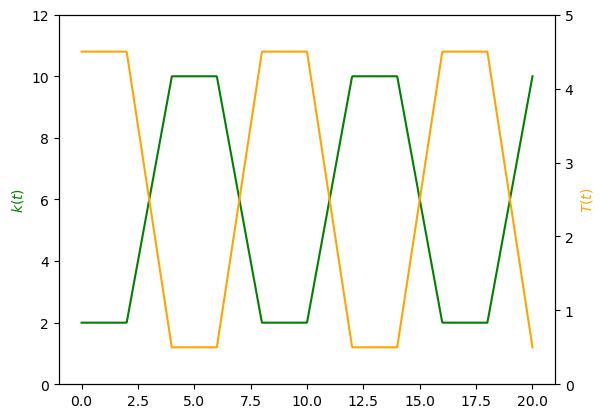

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np

t0 = 2
kmax = 10
kmin = 2
Tmax = 4.5
Tmin = 0.5

def k(t):
    rem = t % t0
    phase = (t // t0) % 4
    
    conditions = [
        phase == 0,
        phase == 1,
        phase == 2,
        phase == 3
    ]

    choices = [
        kmin,
        kmin + (kmax-kmin) * rem / t0,
        kmax,
        kmax + (kmin-kmax) * rem / t0
    ]

    return np.select(conditions, choices, default = np.nan)

def dk(t):
    rem = t % t0
    phase = (t // t0) % 4
    
    conditions = [
        phase == 0,
        phase == 1,
        phase == 2,
        phase == 3
    ]

    choices = [
        0,
        (kmax-kmin)/t0,
        0,
        (kmin-kmax)/t0
    ]

    return np.select(conditions, choices, default = np.nan)

def T(t):
    rem = t % t0
    phase = (t // t0) % 4

    conditions = [
        phase == 0,
        phase == 1,
        phase == 2,
        phase == 3
    ]

    choices = [
        Tmax,
        Tmax + (Tmin - Tmax) * rem / t0,
        Tmin,
        Tmin + (Tmax - Tmin) * rem / t0
    ]

    return np.select(conditions, choices, default = np.nan)

t = np.linspace(0,20,800)
res = np.empty_like(t)
res2 = np.empty_like(t)
for i in range(len(t)):
    res[i] = k(t[i])
    res2[i] = T(t[i])

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.set(ylim = [0,12]), ax1.set_ylabel(r'$k(t)$',color="green")
ax2.set(ylim = [0,5.0]), ax2.set_ylabel(r'$T(t)$',color="orange")
ax1.plot(t,res, color="green")
ax2.plot(t,res2, color="orange")

To solve the described system, we use the new hybrid method `LSolver.mixed`, which combines overdamped Langevin equation in $x$, while keeping underdamped Langevin equation in $y$.

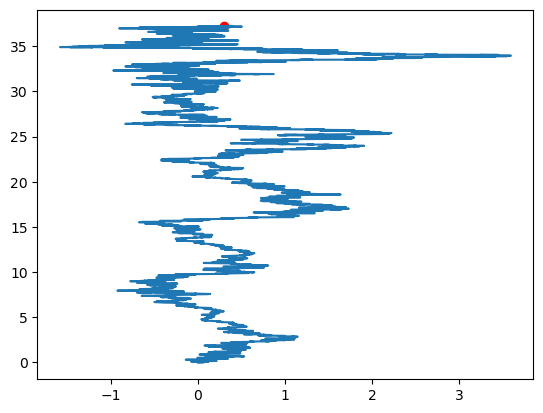

In [4]:
from LSolver import SimulationConfig, mixed

def beta(t):
    return 1/T(t)

gamma = 2.0
m = 8.0
rng = np.random.default_rng(seed=42)

cfg = SimulationConfig(
    gamma = gamma,
    Fx_func = lambda t,x,y: - k(y) * x,
    Fy_func = lambda t,x,y: -(1/2)*dk(y)*x**2,
    Tx_func = lambda t,x,y: T(y),
    Ty_func = lambda t,x,y: Tmin,
    t_max = 20.0,
    dt = 0.001,
    m = m,
    vy0 = 10
)

x, y, vy = mixed(cfg, rng=rng)

fig, ax = plt.subplots(1,1)
ax.plot(x,y)
ax.scatter(x[-1], y[-1], color="red")

## References

[1] Holubec, V., & Ryabov, A. (2018). *Cycling Tames Power Fluctuations near Optimum Efficiency*. Physical Review Letters, 121(12), 120601. [https://doi.org/10.1103/PhysRevLett.121.120601](https://doi.org/10.1103/PhysRevLett.121.120601)